In [ ]:
!pip install --upgrade qiskit qiskit-aer qiskit-ibm-provider
!pip install yfinance pandas numpy matplotlib scipy pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.9/249.9 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 MB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.0/109.0 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 9.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 8.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=9f285627ba4acc02c36466ba9590f321d7fb824eebabc34d43ec435c6d42a917
  Stored 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pylatexenc
import pandas as pd
import seaborn as sns
import yfinance as yf
from IPython.display import display
import matplotlib.pyplot as plt
from scipy.stats import zscore
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import Diagonal, Diagonal, QFT
from qiskit.visualization import plot_histogram

In [ ]:
tickers = [
    "AAPL", "MSFT", "GOOG", "AMZN", "IBM",
    "ORCL", "INTC", "NVDA", "ADBE", "CSCO",
    "CRM", "TXN", "QCOM", "HPQ", "DELL",
    "ACN", "AMD", "AVGO", "SAP", "ADP"
]

metrics = [
    "symbol",
    "shortName",
    "industry",
    "sector",
    "trailingPE",
    "forwardPE",
    "priceToBook",
    "dividendYield",
    "returnOnEquity"
]

data = []

for ticker in tickers:
    try:
        tkr = yf.Ticker(ticker)
        info = tkr.info

        stock_data = {metric: info.get(metric, None) for metric in metrics}

        data.append(stock_data)
    except Exception as e:
        print(f"Error fetching data for {ticker}: {e}")

df = pd.DataFrame(data)

df.reset_index(drop=True, inplace=True)

csv_filename = "tech_stock_data.csv"
df.to_csv(csv_filename, index=False)

print(f"Data for {len(df)} stocks has been successfully saved to '{csv_filename}'.")


Data for 20 stocks has been successfully saved to 'tech_stock_data.csv'.


1. Data Acquisition and Preprocessing

In [ ]:
csv_path = "/content/drive/MyDrive/Winter 2025/CPS840/Research /tech_stock_data.csv"
stock_data = pd.read_csv(csv_path)
print(stock_data)

   symbol                        shortName                         industry  \
0    AAPL                       Apple Inc.             Consumer Electronics   
1    MSFT            Microsoft Corporation        Software - Infrastructure   
2    GOOG                    Alphabet Inc.   Internet Content & Information   
3    AMZN                 Amazon.com, Inc.                  Internet Retail   
4     IBM  International Business Machines  Information Technology Services   
5    ORCL               Oracle Corporation        Software - Infrastructure   
6    INTC                Intel Corporation                   Semiconductors   
7    NVDA               NVIDIA Corporation                   Semiconductors   
8    ADBE                       Adobe Inc.           Software - Application   
9    CSCO              Cisco Systems, Inc.          Communication Equipment   
10    CRM                 Salesforce, Inc.           Software - Application   
11    TXN   Texas Instruments Incorporated          

2. ADAPTIVE OUTLIER DETECTION:
If no outliers found for the current threshold, we lower it until we get some.

In [ ]:
def preprocess_data(df, threshold=2.0, threshold_step=0.25, min_threshold=0.5):

    metrics = ['trailingPE', 'returnOnEquity', 'dividendYield']

    current_threshold = threshold
    while True:
        temp_df = df.copy()
        for metric in metrics:
            temp_df[metric] = temp_df[metric].fillna(temp_df[metric].median())
            temp_df[f'{metric}_z'] = zscore(temp_df[metric])
            temp_df[f'{metric}_outlier'] = temp_df[f'{metric}_z'].apply(lambda x: 1 if abs(x) > current_threshold else 0)
        temp_df['CompositeScore'] = temp_df[[f'{m}_outlier' for m in metrics]].sum(axis=1)

        # Calculate total number of outlier flags across all stocks and metrics
        total_outliers = temp_df[[f'{m}_outlier' for m in metrics]].sum().sum()
        if total_outliers > 0 or current_threshold <= min_threshold:
            print(f"Using threshold={current_threshold:.2f}, found {total_outliers} total outlier flags.")
            return temp_df
        else:
            current_threshold -= threshold_step
            if current_threshold < min_threshold:
                current_threshold = min_threshold

stock_data.columns = stock_data.columns.str.strip()

# Run preprocessing
processed_data = preprocess_data(stock_data, threshold=2.0, threshold_step=0.25, min_threshold=0.5)
print("Preprocessed stock data with outlier indicators:")

print(processed_data[['symbol', 'trailingPE_outlier', 'returnOnEquity_outlier', 'dividendYield_outlier', 'CompositeScore']])


Using threshold=2.00, found 6 total outlier flags.
Preprocessed stock data with outlier indicators:
   symbol  trailingPE_outlier  returnOnEquity_outlier  dividendYield_outlier  \
0    AAPL                   0                       1                      0   
1    MSFT                   0                       0                      0   
2    GOOG                   0                       0                      0   
3    AMZN                   0                       0                      0   
4     IBM                   0                       0                      0   
5    ORCL                   0                       0                      0   
6    INTC                   0                       0                      0   
7    NVDA                   0                       1                      0   
8    ADBE                   0                       0                      0   
9    CSCO                   0                       0                      0   
10    CRM           

3. BUILD THE ORACLES

Oracle Circuit


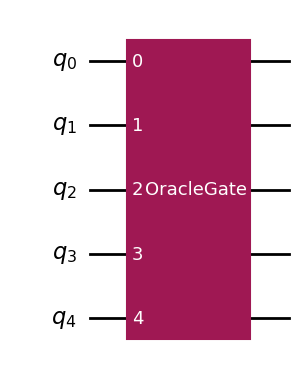

In [ ]:
num_system_qubits = 5  # enough for 20 stocks (2^5 = 32)
dim = 2 ** num_system_qubits

def get_outlier_indices(df, metric_column):
    return df.index[df[metric_column] == 1].tolist()
pe_outliers = get_outlier_indices(processed_data, 'trailingPE_outlier')
roe_outliers = get_outlier_indices(processed_data, 'returnOnEquity_outlier')
dividend_outliers = get_outlier_indices(processed_data, 'dividendYield_outlier')


def create_oracle(outlier_indices):
    diagonal = [(-1 if i in outlier_indices else 1) for i in range(dim)]
    oracle_diag = Diagonal(np.array(diagonal))
    return oracle_diag.to_gate(label="OracleGate")

oracle_pe = create_oracle(pe_outliers)
oracle_roe = create_oracle(roe_outliers)
oracle_dividend = create_oracle(dividend_outliers)

def print_oracle_circuit(oracle_gate, n_qubits=5, title="Oracle Circuit"):
    qc = QuantumCircuit(n_qubits)
    qc.append(oracle_gate, range(n_qubits))
    print(title)
    display(qc.draw("mpl"))

print_oracle_circuit(oracle_pe, n_qubits=5, title="Oracle Circuit")


4. STANDARD GROVER'S ALGORITHM

=== Standard Grover Circuit ===


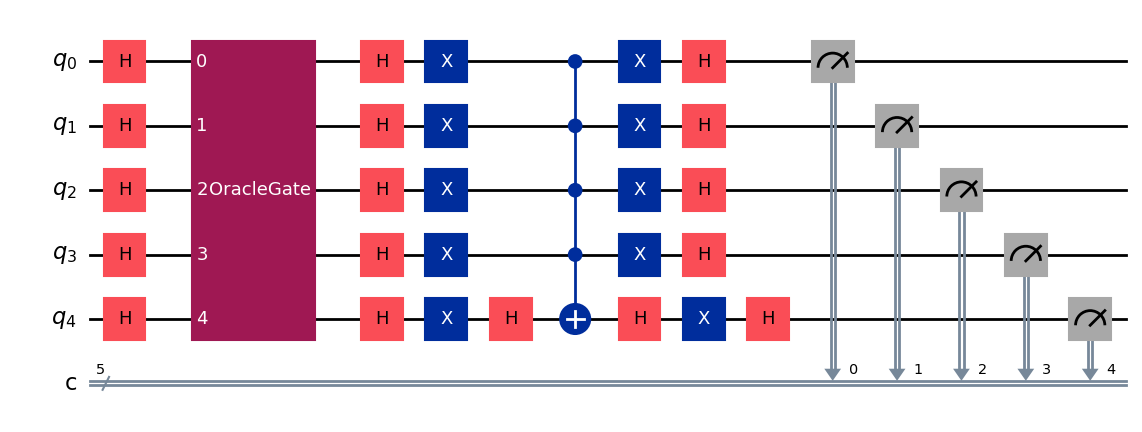

In [ ]:
def grover_circuit(oracle_gate, n_qubits=5, num_iterations=1):
    qc = QuantumCircuit(n_qubits, n_qubits)
    qc.h(range(n_qubits))

    for _ in range(num_iterations):
        # Oracle
        qc.append(oracle_gate, range(n_qubits))
        # Diffusion
        qc.h(range(n_qubits))
        qc.x(range(n_qubits))
        qc.h(n_qubits - 1)
        qc.mcx(list(range(n_qubits - 1)), n_qubits - 1, mode='noancilla')
        qc.h(n_qubits - 1)
        qc.x(range(n_qubits))
        qc.h(range(n_qubits))

    qc.measure(range(n_qubits), range(n_qubits))
    return qc

qc_pe = grover_circuit(oracle_pe, n_qubits=num_system_qubits, num_iterations=1)
qc_roe = grover_circuit(oracle_roe, n_qubits=num_system_qubits, num_iterations=1)
qc_dividend = grover_circuit(oracle_dividend, n_qubits=num_system_qubits, num_iterations=1)

# Standard Grover Circuits
print("=== Standard Grover Circuit ===")
display(qc_pe.draw("mpl"))

5. QUANTUM COUNTING IMPLEMENTATION


=== Quantum Counting Circuit ===


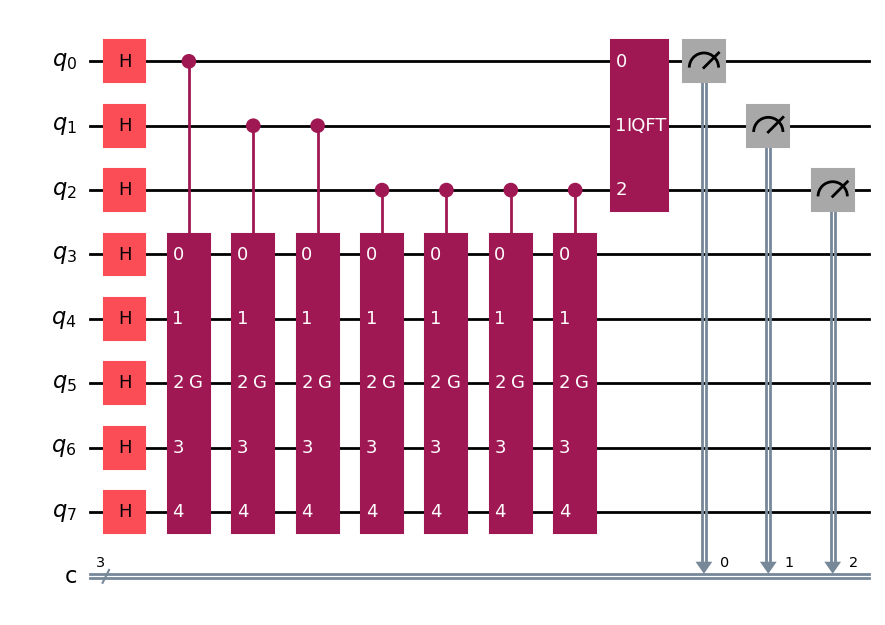

In [ ]:
def build_grover_operator(oracle_gate, n_qubits):
    """
    G = Diffusion * Oracle
    Returns a gate that can be controlled by counting qubits.
    """
    grover_qc = QuantumCircuit(n_qubits, name="GroverOp")
    # Oracle
    grover_qc.append(oracle_gate, range(n_qubits))
    # Diffusion
    grover_qc.h(range(n_qubits))
    grover_qc.x(range(n_qubits))
    grover_qc.h(n_qubits - 1)
    grover_qc.mcx(list(range(n_qubits - 1)), n_qubits - 1, mode='noancilla')
    grover_qc.h(n_qubits - 1)
    grover_qc.x(range(n_qubits))
    grover_qc.h(range(n_qubits))
    return grover_qc.to_gate(label="G")

def quantum_counting_circuit(oracle_gate, n_system_qubits=5, t_count=3):
    """
    t_count: number of counting qubits
    n_system_qubits: the system qubits
    """
    total_qubits = t_count + n_system_qubits
    qc = QuantumCircuit(total_qubits, t_count)

    counting_qubits = range(t_count)
    system_qubits = range(t_count, t_count + n_system_qubits)

    # 1. Put counting qubits in superposition
    qc.h(counting_qubits)

    # 2. Put system qubits in superposition
    qc.h(system_qubits)

    # 3. Build the Grover operator as a gate
    grover_gate = build_grover_operator(oracle_gate, n_system_qubits)

    # 4. Controlled-G repeated 2^k times for each counting qubit k
    for i in range(t_count):
        reps = 2 ** i
        for _ in range(reps):
            controlled_g = grover_gate.control(1)
            qc.append(controlled_g, [counting_qubits[i]] + list(system_qubits))

    # 5. Inverse QFT on counting qubits
    qc.append(QFT(t_count, do_swaps=True).inverse(), counting_qubits)

    # 6. Measure counting qubits
    qc.measure(counting_qubits, range(t_count))

    return qc

qc_count_pe = quantum_counting_circuit(oracle_pe, n_system_qubits=5, t_count=3)
qc_count_roe = quantum_counting_circuit(oracle_roe, n_system_qubits=5, t_count=3)
qc_count_div = quantum_counting_circuit(oracle_dividend, n_system_qubits=5, t_count=3)

# Quantum Counting Circuits
print("\n=== Quantum Counting Circuit ===")
display(qc_count_pe.draw("mpl"))

6. RUN SIMULATIONS ON A LOCAL SIMULATOR (AER)

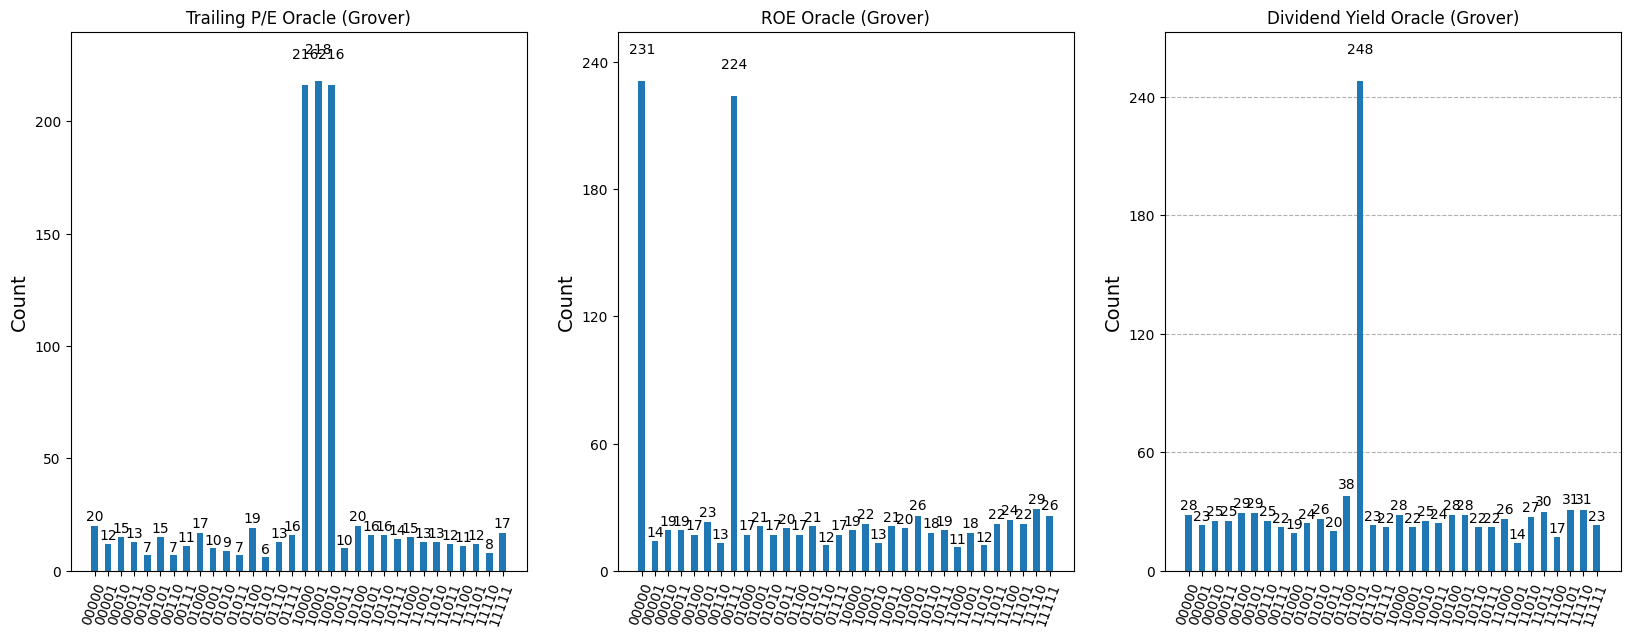

Quantum Counting results (PE): {'001': 20, '100': 56, '010': 25, '000': 33, '110': 22, '111': 18, '011': 410, '101': 440}
Quantum Counting results (ROE): {'110': 40, '001': 23, '000': 30, '010': 37, '111': 21, '011': 356, '101': 301, '100': 216}
Quantum Counting results (Dividend): {'001': 17, '110': 46, '011': 198, '111': 21, '000': 60, '010': 34, '101': 186, '100': 462}


In [ ]:
# simple depolarizing noise model
error = depolarizing_error(0.01, 1)
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(error, ['h', 'x'])

simulator = AerSimulator()

def run_simulation(qc, simulator, noise_model=None, shots=1024):
    compiled_circuit = transpile(qc, simulator)
    job = simulator.run(compiled_circuit, shots=shots, noise_model=noise_model)
    result = job.result()
    counts = result.get_counts(compiled_circuit)
    return counts

# Run standard Grover circuits
counts_pe = run_simulation(qc_pe, simulator, noise_model=noise_model)
counts_roe = run_simulation(qc_roe, simulator, noise_model=noise_model)
counts_dividend = run_simulation(qc_dividend, simulator, noise_model=noise_model)

# Run quantum counting circuits
counts_count_pe = run_simulation(qc_count_pe, simulator, noise_model=noise_model)
counts_count_roe = run_simulation(qc_count_roe, simulator, noise_model=noise_model)
counts_count_div = run_simulation(qc_count_div, simulator, noise_model=noise_model)

# Plot the standard Grover histograms
fig, axes = plt.subplots(1, 3, figsize=(20,7))
plot_histogram(counts_pe, ax=axes[0])
axes[0].set_title("Trailing P/E Oracle (Grover)")
plot_histogram(counts_roe, ax=axes[1])
axes[1].set_title("ROE Oracle (Grover)")
plot_histogram(counts_dividend, ax=axes[2])
axes[2].set_title("Dividend Yield Oracle (Grover)")
plt.show()

# Print quantum counting results
print("Quantum Counting results (PE):", counts_count_pe)
print("Quantum Counting results (ROE):", counts_count_roe)
print("Quantum Counting results (Dividend):", counts_count_div)

7. POST-PROCESSING: INTERPRET THE STANDARD GROVER RESULTS


In [ ]:
def decode_state(state_str):
    return int(state_str, 2)

def combine_counts(counts_list):
    """
    Combine multiple counts dicts into a single composite dictionary
    """
    composite = {}
    for cdict in counts_list:
        for state, cnt in cdict.items():
            composite[state] = composite.get(state, 0) + cnt
    return composite

composite_counts = combine_counts([counts_pe, counts_roe, counts_dividend])
composite_df = pd.DataFrame(list(composite_counts.items()), columns=['State', 'Count'])
composite_df['Index'] = composite_df['State'].apply(lambda s: decode_state(s))
composite_df = composite_df.sort_values('Count', ascending=False)
print("Composite measurement counts (top 7):")
print(composite_df.head(7))

Composite measurement counts (top 7):
    State  Count  Index
18  00000    279      0
2   01101    275     13
9   10000    263     16
5   10001    262     17
25  00111    257      7
12  10010    254     18
7   01100     74     12


8. QUANTUM COUNTING: INTERPRET THE COUNTING REGISTER
Typically, the number of solutions is approx 2^n * sin^2(pi * measured_value / 2^t_count)

In [ ]:
def interpret_counting_result(counts, t_count=3):
    # Find the most common outcome
    best_outcome, best_count = max(counts.items(), key=lambda x: x[1])
    measured_value = int(best_outcome[::-1], 2)
    return best_outcome, measured_value

for name, cdict in [("PE", counts_count_pe), ("ROE", counts_count_roe), ("Dividend", counts_count_div)]:
    outcome, val = interpret_counting_result(cdict, t_count=3)
    # approximate formula for number of marked states
    n = num_system_qubits
    N = 2**n
    M_estimated = N * (np.sin(np.pi * val / (2**3)))**2
    print(f"\n** Quantum Counting for {name} Oracle **")
    print(f"Most common counting outcome = {outcome} (decimal {val})")
    print(f"Estimated # of marked states = {M_estimated:.2f} out of {N} possible.")


** Quantum Counting for PE Oracle **
Most common counting outcome = 101 (decimal 5)
Estimated # of marked states = 27.31 out of 32 possible.

** Quantum Counting for ROE Oracle **
Most common counting outcome = 011 (decimal 6)
Estimated # of marked states = 16.00 out of 32 possible.

** Quantum Counting for Dividend Oracle **
Most common counting outcome = 100 (decimal 1)
Estimated # of marked states = 4.69 out of 32 possible.


COMPOSITE ANALYSIS: HEATMAP & SORTED TABLE

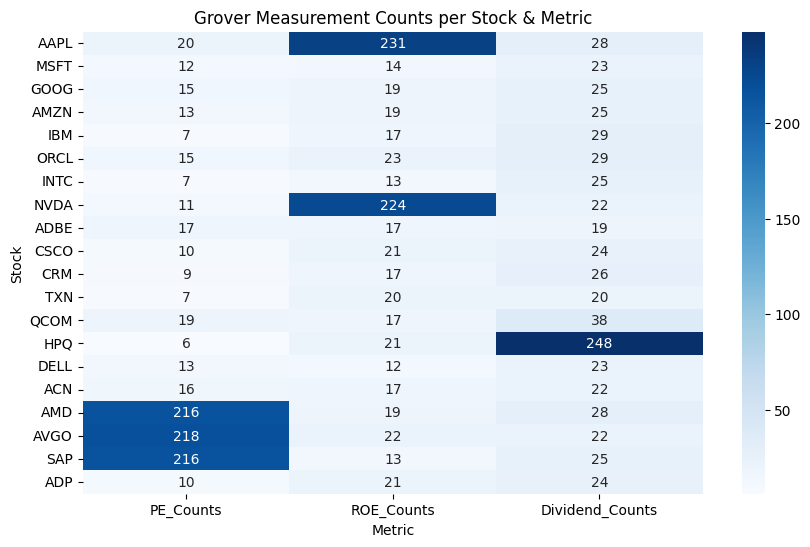


=== Stocks Sorted by Total Measurement Counts (Grover) ===
Ticker  PE_Counts  ROE_Counts  Dividend_Counts  Total
  AAPL         20         231               28    279
   HPQ          6          21              248    275
   AMD        216          19               28    263
  AVGO        218          22               22    262
  NVDA         11         224               22    257
   SAP        216          13               25    254
  QCOM         19          17               38     74
  ORCL         15          23               29     67
  GOOG         15          19               25     59
  AMZN         13          19               25     57
   ADP         10          21               24     55
  CSCO         10          21               24     55
   ACN         16          17               22     55
   IBM          7          17               29     53
  ADBE         17          17               19     53
   CRM          9          17               26     52
  MSFT         12     

In [ ]:
def accumulate_measurements(counts, n_stocks):
    measurements = [0] * n_stocks
    for bitstring, count in counts.items():
        # Convert the bitstring to an integer (base-2).
        index = int(bitstring, 2)
        if index < n_stocks:
            measurements[index] += count
    return measurements

analysis_df = pd.DataFrame({
    "Ticker": processed_data["symbol"],
    "PE_Counts": accumulate_measurements(counts_pe, len(processed_data)),
    "ROE_Counts": accumulate_measurements(counts_roe, len(processed_data)),
    "Dividend_Counts": accumulate_measurements(counts_dividend, len(processed_data))
})
analysis_df["Total"] = analysis_df["PE_Counts"] + analysis_df["ROE_Counts"] + analysis_df["Dividend_Counts"]

# Create heatmap
heatmap_df = analysis_df[["Ticker", "PE_Counts", "ROE_Counts", "Dividend_Counts"]].copy()
heatmap_df = heatmap_df.set_index("Ticker")
plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_df, cmap="Blues", annot=True, fmt="g")
plt.title("Grover Measurement Counts per Stock & Metric")
plt.xlabel("Metric")
plt.ylabel("Stock")
plt.show()

# Print sorted table
analysis_sorted = analysis_df.sort_values("Total", ascending=False)
print("\n=== Stocks Sorted by Total Measurement Counts (Grover) ===")
print(analysis_sorted.to_string(index=False))




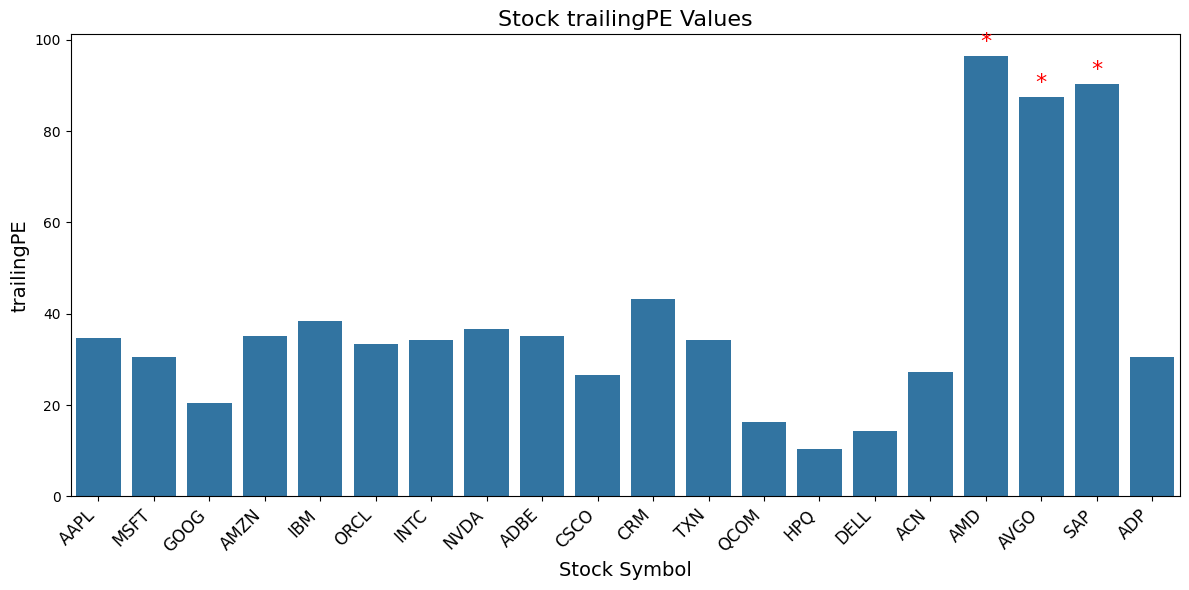

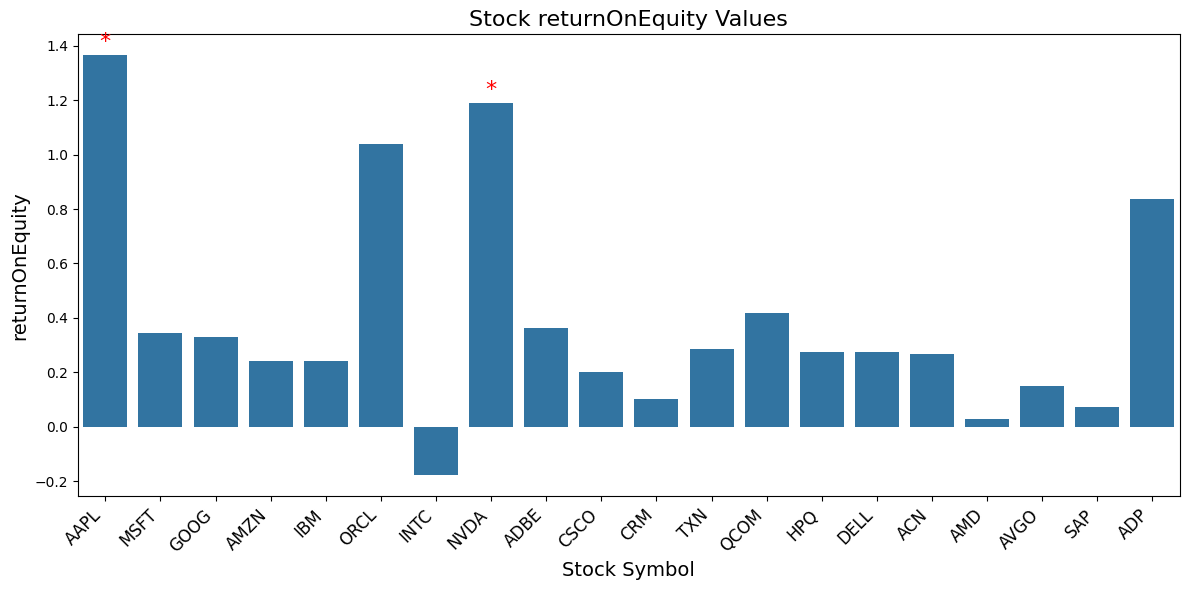

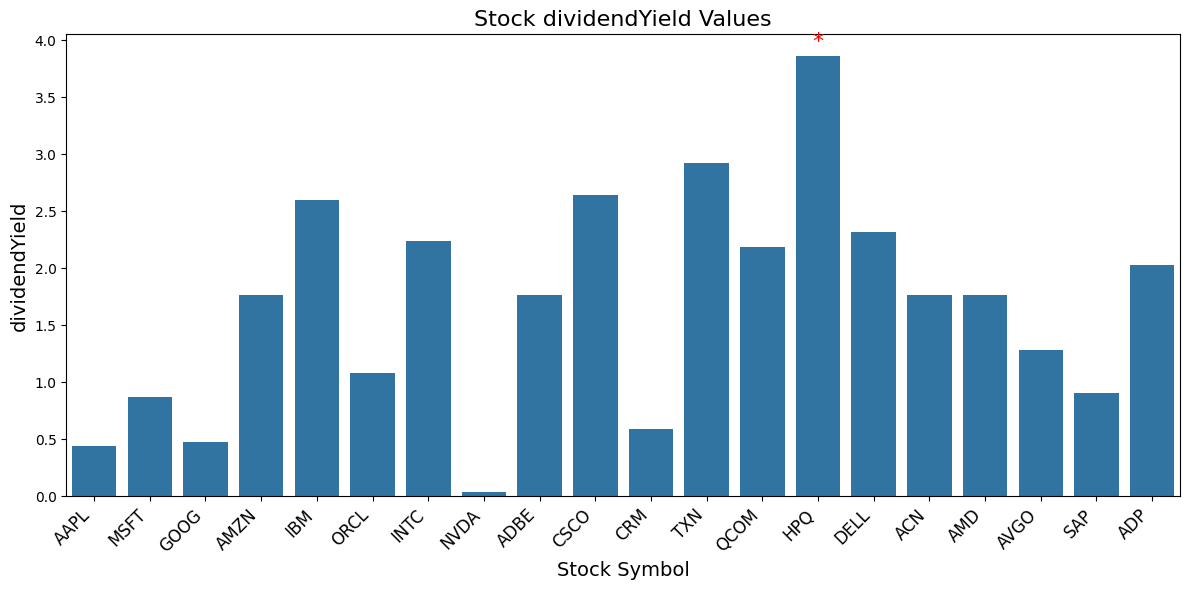


=== Stocks Sorted by Composite Outlier Score ===


,symbol,trailingPE,returnOnEquity,dividendYield,CompositeScore
0,AAPL,34.585712,1.36520,0.44,1
18,SAP,90.372826,0.07062,0.91,1
17,AVGO,87.398150,0.14845,1.28,1
7,NVDA,36.695580,1.19177,0.04,1
16,AMD,96.400000,0.02893,1.77,1
13,HPQ,10.300360,0.27613,3.86,1
1,MSFT,30.503632,0.34291,0.87,0
2,GOOG,20.366915,0.32908,0.48,0
3,AMZN,35.119564,0.24290,1.77,0
4,IBM,38.482864,0.24057,2.60,0


In [ ]:
# Define the metrics we're interested in.
metrics = ['trailingPE', 'returnOnEquity', 'dividendYield']

# Bar Charts with Outlier Markers for each metric
for metric in metrics:
    plt.figure(figsize=(12, 6))
    ax = sns.barplot(x='symbol', y=metric, data=processed_data, legend=False)
    plt.title(f"Stock {metric} Values", fontsize=16)
    plt.xlabel("Stock Symbol", fontsize=14)
    plt.ylabel(metric, fontsize=14)
    plt.xticks(rotation=45, ha='right', fontsize=12)
    # Overlay red asterisks on bars where the outlier flag is 1
    for i, row in processed_data.iterrows():
        outlier_col = f"{metric}_outlier"
        if outlier_col in row and row[outlier_col] == 1:
            ax.text(i, row[metric] + 0.02 * row[metric], "*", color='red', fontsize=16, ha='center')
    plt.tight_layout()
    plt.show()

# Sorting the data so that stocks with higher CompositeScore are on top.
analysis_table = processed_data[["symbol", "trailingPE", "returnOnEquity", "dividendYield", "CompositeScore"]].sort_values("CompositeScore", ascending=False)
print("\n=== Stocks Sorted by Composite Outlier Score ===")
display(analysis_table)